<a href="https://colab.research.google.com/github/asema405/Maachine_Learning/blob/main/ML_PR6_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("Бардык китепканалар жүктөлдү!")

Бардык китепканалар жүктөлдү!


In [3]:
dataset = load_dataset("cornell-movie-review-data/rotten_tomatoes")

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

df = pd.concat([train_df, test_df], ignore_index=True)

df["sentiment"] = df["label"].map({
    0: "negative",
    1: "positive"
})

print("Train саптары:", len(train_df))
print("Test саптары:", len(test_df))
print("Жалпы саптар:", len(df))

display(df.head())

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Train саптары: 8530
Test саптары: 1066
Жалпы саптар: 9596


,text,label,sentiment
0,the rock is destined to be the 21st century's ...,1,positive
1,"the gorgeously elaborate continuation of "" the...",1,positive
2,effective but too-tepid biopic,1,positive
3,if you sometimes like to go to the movies to h...,1,positive
4,"emerges as something rare , an issue movie tha...",1,positive


Класстардын саны:
sentiment
positive    4798
negative    4798
Name: count, dtype: int64


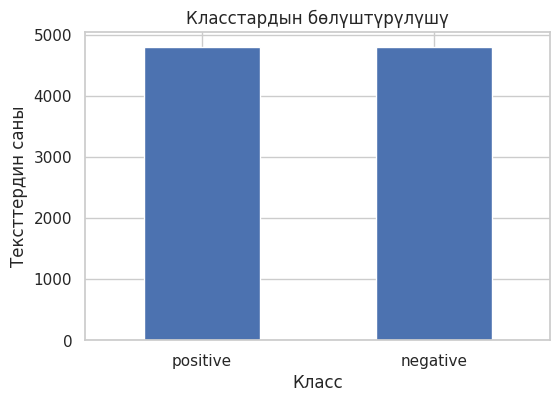

In [4]:
print("Класстардын саны:")
print(df["sentiment"].value_counts())

df["sentiment"].value_counts().plot(
    kind="bar",
    figsize=(6, 4),
    title="Класстардын бөлүштүрүлүшү"
)

plt.xlabel("Класс")
plt.ylabel("Тексттердин саны")
plt.xticks(rotation=0)
plt.show()

In [5]:
# Англис тилиндеги стоп-сөздөрдүн окуу үчүн түзүлгөн тизмеси
stop_words = {
    "the", "a", "an", "is", "are", "was", "were",
    "to", "of", "in", "on", "at", "for", "and",
    "or", "but", "with", "this", "that", "these",
    "those", "it", "its", "as", "by", "from",
    "be", "been", "being", "have", "has", "had",
    "do", "does", "did", "i", "you", "he", "she",
    "we", "they", "my", "your", "our", "their"
}

def clean_text(text):
    text = str(text).lower()

    # URL дарды алып салуу
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Пунктуацияны жана цифраларды алып салуу
    text = re.sub(r"[^a-z\s]", " ", text)

    # Токенизация жана стоп-сөздөрдү алып салуу
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]

    return " ".join(tokens)

In [6]:
examples = [
    "This movie is NOT good!!! 2024",
    "The film was wonderful and very interesting.",
    "I do not recommend this movie."
]

for text in examples:
    print("Баштапкы текст:", text)
    print("Тазаланган текст:", clean_text(text))
    print("-" * 60)

Баштапкы текст: This movie is NOT good!!! 2024
Тазаланган текст: movie not good
------------------------------------------------------------
Баштапкы текст: The film was wonderful and very interesting.
Тазаланган текст: film wonderful very interesting
------------------------------------------------------------
Баштапкы текст: I do not recommend this movie.
Тазаланган текст: not recommend movie
------------------------------------------------------------


In [7]:
train_df = train_df.copy()
test_df = test_df.copy()

train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

print("Баштапкы жана тазаланган тексттер:")
display(train_df[["text", "clean_text", "label"]].head(10))

Баштапкы жана тазаланган тексттер:


,text,clean_text,label
0,the rock is destined to be the 21st century's ...,rock destined st century s new conan s going m...,1
1,"the gorgeously elaborate continuation of "" the...",gorgeously elaborate continuation lord rings t...,1
2,effective but too-tepid biopic,effective too tepid biopic,1
3,if you sometimes like to go to the movies to h...,if sometimes like go movies fun wasabi good pl...,1
4,"emerges as something rare , an issue movie tha...",emerges something rare issue movie s so honest...,1
5,the film provides some great insight into the ...,film provides some great insight into neurotic...,1
6,offers that rare combination of entertainment ...,offers rare combination entertainment education,1
7,perhaps no picture ever made has more literall...,perhaps no picture ever made more literally sh...,1
8,steers turns in a snappy screenplay that curls...,steers turns snappy screenplay curls edges s s...,1
9,take care of my cat offers a refreshingly diff...,take care cat offers refreshingly different sl...,1


In [8]:
X_train_text = train_df["clean_text"]
y_train = train_df["label"]

X_test_text = test_df["clean_text"]
y_test = test_df["label"]

vectorizer = TfidfVectorizer(
    min_df=2,
    max_df=0.95,
    max_features=10000,
    ngram_range=(1, 2)
)

# Векторизаторду train маалыматында гана үйрөтөбүз
X_train = vectorizer.fit_transform(X_train_text)

# Test маалыматында fit эмес, transform гана колдонулат
X_test = vectorizer.transform(X_test_text)

print("Train матрицасынын өлчөмү:", X_train.shape)
print("Test матрицасынын өлчөмү:", X_test.shape)
print("Сөздүктөгү белгилердин саны:", len(vectorizer.get_feature_names_out()))

Train матрицасынын өлчөмү: (8530, 10000)
Test матрицасынын өлчөмү: (1066, 10000)
Сөздүктөгү белгилердин саны: 10000


In [9]:
model = MultinomialNB(alpha=1.0)

model.fit(X_train, y_train)

print("Naive Bayes модели окутулду!")

Naive Bayes модели окутулду!


In [10]:
y_pred = model.predict(X_test)

print("Биринчи 10 чыныгы класс:")
print(y_test.iloc[:10].to_list())

print("\nБиринчи 10 божомол:")
print(y_pred[:10].tolist())

Биринчи 10 чыныгы класс:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Биринчи 10 божомол:
[1, 1, 0, 1, 1, 1, 1, 0, 1, 0]


In [11]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nТолук классификация отчёту:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

Accuracy:  0.7880
Precision: 0.7935
Recall:    0.7786
F1-score:  0.7860

Толук классификация отчёту:
              precision    recall  f1-score   support

    Negative       0.78      0.80      0.79       533
    Positive       0.79      0.78      0.79       533

    accuracy                           0.79      1066
   macro avg       0.79      0.79      0.79      1066
weighted avg       0.79      0.79      0.79      1066



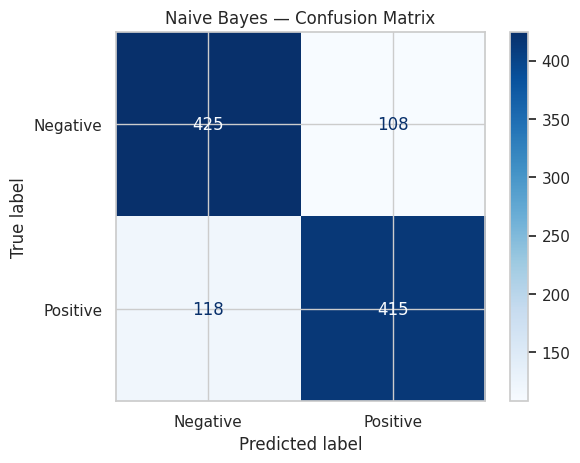

Матрицанын маанилери:
[[425 108]
 [118 415]]


In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes — Confusion Matrix")
plt.show()

print("Матрицанын маанилери:")
print(cm)

In [13]:
error_df = test_df[["text", "clean_text", "label"]].copy()
error_df["predicted"] = y_pred

error_df["true_label"] = error_df["label"].map({
    0: "Negative",
    1: "Positive"
})

error_df["predicted_label"] = error_df["predicted"].map({
    0: "Negative",
    1: "Positive"
})

errors = error_df[
    error_df["label"] != error_df["predicted"]
].copy()

print("Жалпы туура эмес классификацияланган тексттер:", len(errors))

if len(errors) > 0:
    display(errors[[
        "text",
        "clean_text",
        "true_label",
        "predicted_label"
    ]].head(5))
else:
    print("Бул тест топтомунда ката классификация табылган жок.")

Жалпы туура эмес классификацияланган тексттер: 226


,text,clean_text,true_label,predicted_label
2,"it's like a "" big chill "" reunion of the baade...",s like big chill reunion baader meinhof gang o...,Positive,Negative
7,weighty and ponderous but every bit as filling...,weighty ponderous every bit filling treat title,Positive,Negative
9,generates an enormous feeling of empathy for i...,generates enormous feeling empathy characters,Positive,Negative
12,"mostly , [goldbacher] just lets her complicate...",mostly goldbacher just lets her complicated ch...,Positive,Negative
14,"at its worst , the movie is pretty diverting ;...",worst movie pretty diverting pity rarely achie...,Positive,Negative


In [14]:
error_examples = errors.head(5).copy()

def explain_error(row):
    text = row["clean_text"]

    if not text.strip():
        return "Текст тазалоодон кийин бош болуп калган болушу мүмкүн."

    if "not" in text.split() or "no" in text.split():
        return "Терс маанини билдирген сөздөр контекстке жараша туура эмес түшүндүрүлгөн болушу мүмкүн."

    if len(text.split()) <= 5:
        return "Текст өтө кыска болгондуктан, классификация үчүн маалымат жетишсиз болушу мүмкүн."

    return "Ирония, контекст же сөздөрдүн өзгөчө айкалышы модель үчүн түшүнүксүз болгон болушу мүмкүн."

error_examples["Ыктымалдуу себеп"] = error_examples.apply(
    explain_error, axis=1
)

display(error_examples[[
    "text",
    "true_label",
    "predicted_label",
    "Ыктымалдуу себеп"
]])

,text,true_label,predicted_label,Ыктымалдуу себеп
2,"it's like a "" big chill "" reunion of the baade...",Positive,Negative,"Ирония, контекст же сөздөрдүн өзгөчө айкалышы ..."
7,weighty and ponderous but every bit as filling...,Positive,Negative,"Ирония, контекст же сөздөрдүн өзгөчө айкалышы ..."
9,generates an enormous feeling of empathy for i...,Positive,Negative,"Текст өтө кыска болгондуктан, классификация үч..."
12,"mostly , [goldbacher] just lets her complicate...",Positive,Negative,"Ирония, контекст же сөздөрдүн өзгөчө айкалышы ..."
14,"at its worst , the movie is pretty diverting ;...",Positive,Negative,"Ирония, контекст же сөздөрдүн өзгөчө айкалышы ..."


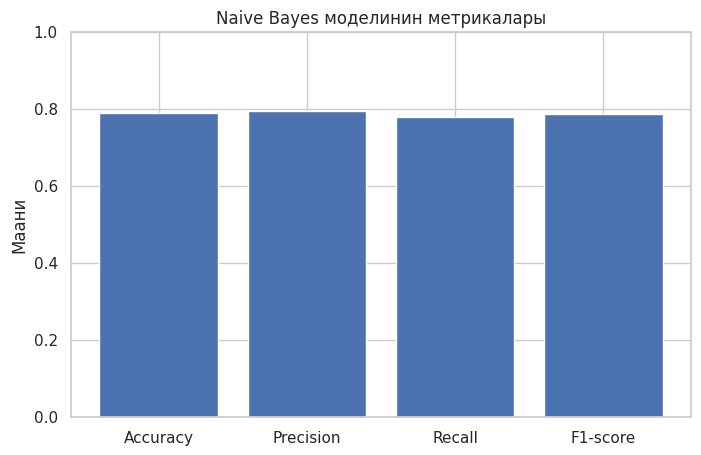

In [15]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}

plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), metrics.values())
plt.ylim(0, 1)
plt.title("Naive Bayes моделинин метрикалары")
plt.ylabel("Маани")
plt.show()

# Практическая работа № 6. Классификация текстов

## 1. Цель работы

Освоить основные этапы обработки текстовых данных, реализовать очистку и нормализацию текста, выполнить TF-IDF-векторизацию и обучить классификатор на основе наивного байесовского алгоритма.

## 2. Используемые данные

В работе использован корпус `rotten_tomatoes`, содержащий короткие отзывы о фильмах с двумя классами тональности: отрицательными и положительными.

- `0` — отрицательный отзыв;
- `1` — положительный отзыв.

Для обучения использована обучающая выборка, для итоговой оценки — отдельная тестовая выборка.

## 3. Предобработка текста

Реализована функция очистки текста, которая выполняет следующие действия:

1. Приведение текста к нижнему регистру.
2. Удаление URL.
3. Удаление пунктуации и цифр.
4. Токенизация текста.
5. Удаление выбранных стоп-слов.

Слова, выражающие отрицание, например `not` и `no`, сохранены, поскольку они могут влиять на тональность отзыва.

Стемминг и лемматизация не применялись.

## 4. Векторизация

Для преобразования текстов в числовые признаки использован `TfidfVectorizer` со следующими параметрами:

- `min_df = 2`;
- `max_df = 0.95`;
- `max_features = 10000`;
- `ngram_range = (1, 2)`.

Размерность обучающей матрицы: **[вставить результат X_train.shape]**.

Размерность тестовой матрицы: **[вставить результат X_test.shape]**.

Векторизатор обучался только на обучающих текстах, после чего применялся к тестовым данным. Это позволило избежать утечки данных.

## 5. Модель и оценка качества

Для классификации использован алгоритм `MultinomialNB` с параметром `alpha = 1.0`.

Результаты на тестовой выборке:

- Accuracy: **[вставить результат]**;
- Precision: **[вставить результат]**;
- Recall: **[вставить результат]**;
- F1-score: **[вставить результат]**.

Accuracy показывает общую долю правильных предсказаний, а F1-score учитывает баланс между Precision и Recall.

## 6. Анализ ошибок

Были найдены и изучены пять текстов, которые модель классифицировала неправильно.

Для каждого примера рассмотрены истинная метка, предсказанный класс и возможная причина ошибки. Возможные причины: недостаток контекста, ирония, отрицания, неоднозначные выражения и короткая длина отзыва.

## 7. Вывод

В ходе работы был реализован базовый конвейер классификации текстов: очистка, нормализация, TF-IDF-векторизация и обучение наивного байесовского классификатора.

Качество модели оценено с помощью Accuracy, Precision, Recall и F1-score. Также выполнен анализ ошибок на тестовых данных.

Работа показала, что качество классификации зависит не только от алгоритма, но и от качества предобработки текста, выбора признаков и особенностей языка отзывов.
